# Review all workspaces

In [ ]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.append("../functions")
from groups import get_all_groups_data, merge_groups_data
from workspace import extract_config_values

# Settings


In [3]:
# Enter location of data
share_dir = Path(extract_config_values().get("collaborators_dir"))

# Decide whether you want the outputs to be saved and in which format
save_results = False
save_format = "svg"

# Define where the outputs will be saved
output_dir = share_dir / "__summary_outputs"

if save_results:
    output_dir.mkdir(parents=True, exist_ok=True)
    print(f"All results will be saved to: {output_dir}")

# Import Data

In [23]:
groups = get_all_groups_data(share_dir)

Processed data from IRSS in BurkinaFaso for workspace(s) MMS2024
Processed data from CRID in Cameroon for workspace(s) icemr, training-summary
Processed data from UniYaounde in Cameroon for workspace(s) btc-uy1-camgen
Processed data from UCB in DemRepCongo for workspace(s) MARS
Processed data from UniKinshasa in DemRepCongo for workspace(s) training
No summaries identified from BIMEP in EqGuinea
No summaries identified from CHARITE in Ethiopia
No summaries identified from CRML in Gabon
No summaries identified from CHUB_RKI in IvCoast
Processed data from KCL in Kenya for workspace(s) ATSB
Processed data from KCL in Kenya for workspace(s) ATSB_edited
Processed data from KCL in Kenya for workspace(s) ASH_2026
No summaries identified from KEMRI_Ento in Kenya
No summaries identified from USTTB in Mali
Processed data from UNAM in Namibia for workspace(s) Retrospective_17_21_22_23
No summaries identified from BUK in Nigeria
Processed data from CERID in Nigeria for workspace(s) Nigeria-LTCH
No

In [24]:
replicates_df = merge_groups_data(groups, "replicates_df")
samples_qc_df = merge_groups_data(groups, "samples_qc_df")

# Create useful dataframes

In [25]:
group_keys = ["country", "group"]

per_group_df = (
    samples_qc_df
    .assign(is_passing=samples_qc_df["status"].eq("passing"))
    .groupby(group_keys, as_index=False)
    .agg(
        n_samples=("status", "count"),
        n_samples_passed=("is_passing", "sum"),
    )
)

In [26]:
expt_keys = ["country", "group", "expt_name"]

num_cols = replicates_df.select_dtypes("number").columns.difference(expt_keys)
agg = {c: "sum" for c in num_cols}
agg["date"] = "min"

agg_named = {col: (col, func) for col, func in agg.items()}

per_expt_df = (
    replicates_df
    .groupby(expt_keys, as_index=False)
    .agg(
        **agg_named,
        n_samples=("passing", "count"),
        n_samples_passed=("passing", "sum"),
    )
)

per_expt_df["date"] = pd.to_datetime(per_expt_df["date"])
per_expt_df.rename(columns={"n_fail_contam": "n_amplicons_fail_contam", 
                            "n_fail_lowcov": "n_amplicons_fail_lowcov",
                            "n_passing": "n_amplicons_passed"}, inplace=True)

# Plots

##### Number of samples processed

Text(0.5, 0, 'Number of samples processed')

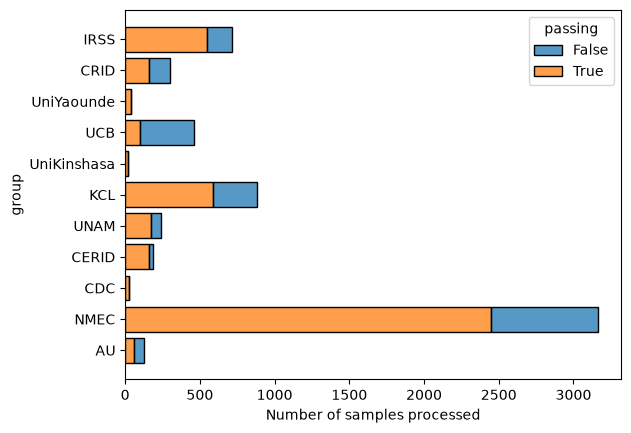

In [27]:
ax = sns.histplot(
    data=replicates_df,
    y="group",
    hue="passing",
    multiple="stack",
    discrete=True,
    shrink=0.8,
)
ax.xaxis.set_label_text("Number of samples processed")

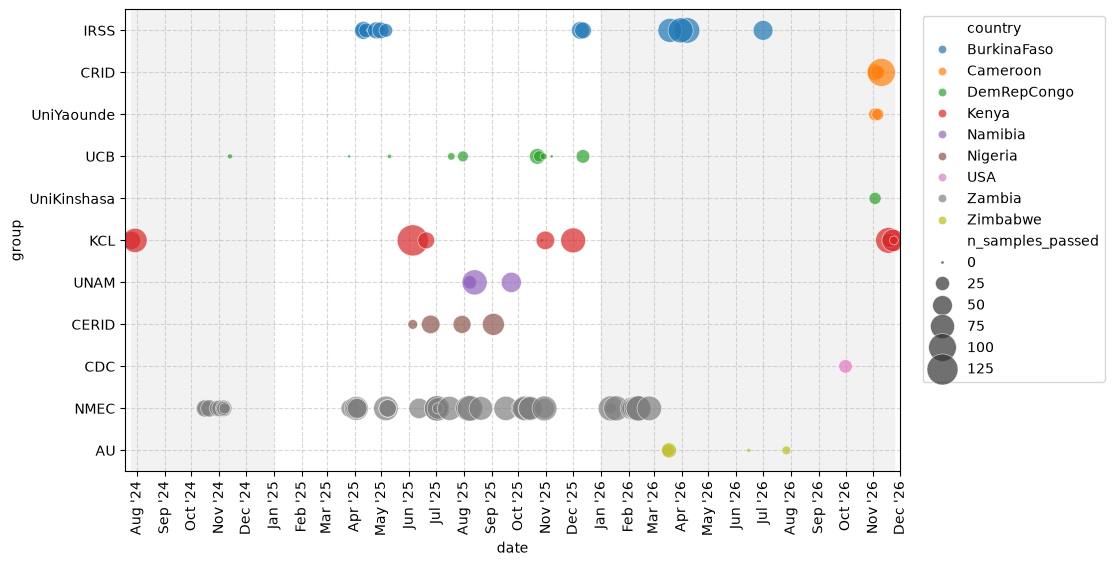

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))

min_date = per_expt_df["date"].min()
max_date = per_expt_df["date"].max()

# Alternating greyscale background by year, clipped to the data range
greyscale_shades = ["#f2f2f2", "#ffffff"]
for i, year in enumerate(range(min_date.year, max_date.year + 1)):
    start_date = max(pd.Timestamp(f"{year}-01-01"), min_date)
    end_date = min(pd.Timestamp(f"{year}-12-31"), max_date)
    ax.axvspan(start_date, end_date, color=greyscale_shades[i % 2], zorder=0)

# Scatter plot
sns.scatterplot(
    data=per_expt_df,
    x="date",
    y="group",
    size="n_samples_passed",
    sizes=(5, 500),
    hue="country",
    legend="brief",
    zorder=2,
    ax=ax,
    alpha=0.7
)

ax.grid(True, which="major", linestyle="--", alpha=0.5, zorder=1)

# Pad Axis limits
pad = pd.Timedelta(days=7)
ax.set_xlim(min_date - pad, max_date + pad)

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
_ = plt.setp(ax.get_xticklabels(), rotation=90, ha="center")

sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1))